
# Telecom Customer Churn Prediction and Retention Optimization

## 01 - Data Understanding

### Objective

Understand the structure, characteristics and quality of
the raw telecommunications customer dataset before
performing data cleaning and analysis.

### Dataset

Iranian Customer Churn Dataset - UCI Machine Learning Repository.

### Tasks

- Import required libraries
- Load the raw dataset
- Inspect customer records
- Identify dataset dimensions
- Examine column names and data types
- Identify missing values
- Investigate duplicate records
- Examine descriptive statistics
- Understand the churn target variable


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import sys

print("Libraries imported successfully!")
print("Python interpreter:", sys.executable)

Libraries imported successfully!
Python interpreter: c:\Users\kavin\OneDrive - University of Kelaniya\Desktop\telecom-churn-retention-intelligence\.venv\Scripts\python.exe


In [12]:
# Identify project directory
project_root = Path.cwd()

if not (project_root / "data").is_dir():
    project_root = project_root.parent

# Define dataset path
data_path = project_root / "data" / "raw" / "Customer Churn.csv"

# Load dataset
df = pd.read_csv(data_path)

# Clean column names
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()

print("Dataset loaded successfully!")
print("Column names cleaned successfully!")

print(df.columns.tolist())

Dataset loaded successfully!
Column names cleaned successfully!
['Call Failure', 'Complains', 'Subscription Length', 'Charge Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']


In [3]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 3150
Number of columns: 14


## 2. Dataset Column Names

Identify all available customer attributes and the
target variable.

In [5]:
print("Dataset columns:")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Dataset columns:
1. Call  Failure
2. Complains
3. Subscription  Length
4. Charge  Amount
5. Seconds of Use
6. Frequency of use
7. Frequency of SMS
8. Distinct Called Numbers
9. Age Group
10. Tariff Plan
11. Status
12. Age
13. Customer Value
14. Churn


## 3. Dataset Information and Data Types

Examine the data types, non-null counts and memory
usage of the dataset.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

## 4. Missing Value Analysis

Identify missing values in each column and calculate
the percentage of missing observations.

In [7]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_values

,Missing Count,Missing Percentage
Call Failure,0,0.0
Complains,0,0.0
Subscription Length,0,0.0
Charge Amount,0,0.0
Seconds of Use,0,0.0
Frequency of use,0,0.0
Frequency of SMS,0,0.0
Distinct Called Numbers,0,0.0
Age Group,0,0.0
Tariff Plan,0,0.0


## 5. Duplicate Record Analysis

Identify identical records and investigate potential
data quality issues.

In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

print(
    "Duplicate percentage:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Number of duplicate rows: 300
Duplicate percentage: 9.52 %


In [9]:
df[df.duplicated(keep=False)].head(10)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0
5,11,0,38,1,3775,82,32,28,3,1,1,30,282.280,0
6,4,0,38,0,2360,39,285,18,3,1,1,30,1235.960,0
7,13,0,37,2,9115,121,144,43,3,1,1,30,945.440,0
8,7,0,38,0,13773,169,0,44,3,1,1,30,557.680,0
9,7,0,38,1,4515,83,2,25,3,1,1,30,191.920,0


## 6. Descriptive Statistics

Examine the distribution, central tendency and
variability of numerical variables.

In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.63,7.26,0.0,1.00,6.00,12.00,36.00
Complains,3150.0,0.08,0.27,0.0,0.00,0.00,0.00,1.00
Subscription Length,3150.0,32.54,8.57,3.0,30.00,35.00,38.00,47.00
Charge Amount,3150.0,0.94,1.52,0.0,0.00,0.00,1.00,10.00
Seconds of Use,3150.0,4472.46,4197.91,0.0,1391.25,2990.00,6478.25,17090.00
Frequency of use,3150.0,69.46,57.41,0.0,27.00,54.00,95.00,255.00
Frequency of SMS,3150.0,73.17,112.24,0.0,6.00,21.00,87.00,522.00
Distinct Called Numbers,3150.0,23.51,17.22,0.0,10.00,21.00,34.00,97.00
Age Group,3150.0,2.83,0.89,1.0,2.00,3.00,3.00,5.00
Tariff Plan,3150.0,1.08,0.27,1.0,1.00,1.00,1.00,2.00


## 7. Categorical Variable Analysis

Identify the unique categories available in the
customer dataset.

In [14]:
categorical_columns = [
    "Complains",
    "Age Group",
    "Charge Amount",
    "Tariff Plan",
    "Status",
    "Churn"
]

for column in categorical_columns:
    print(column, ":", sorted(df[column].unique().tolist()))

Complains : [0, 1]
Age Group : [1, 2, 3, 4, 5]
Charge Amount : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Tariff Plan : [1, 2]
Status : [1, 2]
Churn : [0, 1]


## 8. Target Variable Analysis

Examine the distribution of churned and non-churned
customers to identify potential class imbalance.

In [ ]:
churn_distribution = pd.DataFrame({
    "Customer Count": df["Churn"].value_counts(),
    "Percentage": (
        df["Churn"].value_counts(normalize=True) * 100
    ).round(2)
})

churn_distribution.index = churn_distribution.index.map({
    0: "Non-Churned",
    1: "Churned"
})

churn_distribution

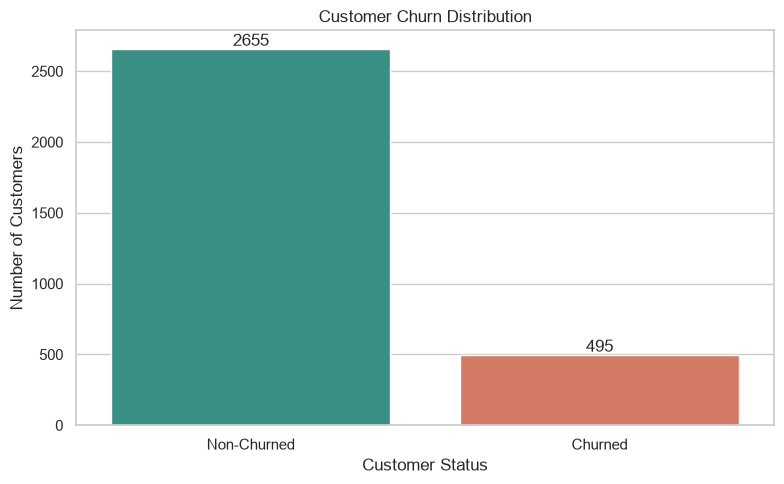

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette=["#2A9D8F", "#E76F51"],
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Non-Churned", "Churned"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## 10. Initial Data Quality Summary

Summarize the dataset structure and identify potential
data quality issues before data cleaning.

In [16]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Total Missing Values",
        "Duplicate Rows",
        "Churned Customers",
        "Non-Churned Customers",
        "Churn Rate (%)"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        (df["Churn"] == 1).sum(),
        (df["Churn"] == 0).sum(),
        round(df["Churn"].mean() * 100, 2)
    ]
})

quality_summary

,Metric,Value
0,Total Records,3150.00
1,Total Columns,14.00
2,Total Missing Values,0.00
3,Duplicate Rows,300.00
4,Churned Customers,495.00
5,Non-Churned Customers,2655.00
6,Churn Rate (%),15.71


In [17]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Total Missing Values",
        "Duplicate Rows",
        "Churned Customers",
        "Non-Churned Customers",
        "Churn Rate (%)"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        (df["Churn"] == 1).sum(),
        (df["Churn"] == 0).sum(),
        round(df["Churn"].mean() * 100, 2)
    ]
})

quality_summary

,Metric,Value
0,Total Records,3150.00
1,Total Columns,14.00
2,Total Missing Values,0.00
3,Duplicate Rows,300.00
4,Churned Customers,495.00
5,Non-Churned Customers,2655.00
6,Churn Rate (%),15.71


## 11. Detailed Duplicate Record Investigation

Investigate identical customer records before making
decisions about duplicate removal.

In [18]:
duplicate_records = df[df.duplicated(keep=False)]

print("Repeated rows beyond first occurrence:",
      df.duplicated().sum())

print("All records involved in duplicate groups:",
      len(duplicate_records))

print("Unique record combinations:",
      len(df.drop_duplicates()))

duplicate_records.head(10)

Repeated rows beyond first occurrence: 300
All records involved in duplicate groups: 465
Unique record combinations: 2850


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0
5,11,0,38,1,3775,82,32,28,3,1,1,30,282.280,0
6,4,0,38,0,2360,39,285,18,3,1,1,30,1235.960,0
7,13,0,37,2,9115,121,144,43,3,1,1,30,945.440,0
8,7,0,38,0,13773,169,0,44,3,1,1,30,557.680,0
9,7,0,38,1,4515,83,2,25,3,1,1,30,191.920,0


In [19]:
duplicate_comparison = pd.DataFrame({
    "Dataset": [
        "Original Dataset",
        "Without Identical Rows"
    ],
    "Total Records": [
        len(df),
        len(df.drop_duplicates())
    ],
    "Churn Rate (%)": [
        round(df["Churn"].mean() * 100, 2),
        round(
            df.drop_duplicates()["Churn"].mean() * 100,
            2
        )
    ]
})

duplicate_comparison

,Dataset,Total Records,Churn Rate (%)
0,Original Dataset,3150,15.71
1,Without Identical Rows,2850,15.65


## 12. Charge Amount Validation

Investigate the difference between the documented
and observed charge amount categories.

In [20]:
print("Minimum charge amount:", df["Charge Amount"].min())

print("Maximum charge amount:", df["Charge Amount"].max())

print("Records with charge amount 10:",
      (df["Charge Amount"] == 10).sum())

df["Charge Amount"].value_counts().sort_index()

Minimum charge amount: 0
Maximum charge amount: 10
Records with charge amount 10: 7


Charge Amount
0     1768
1      617
2      395
3      199
4       76
5       30
6       11
7       14
8       19
9       14
10       7
Name: count, dtype: int64


## 13. Initial Data Profiling Findings

- The dataset contains 3,150 customer records.
- There are 13 input features and one target variable.
- No missing values were identified.
- 300 repeated records were detected beyond their
  first occurrence.
- The repeated record percentage is 9.52%.
- The overall customer churn rate is 15.71%.
- The target variable demonstrates class imbalance.
- Inconsistent whitespace in column names was corrected.
- Charge Amount contains values from 0 to 10,
  although the source documentation specifies 0 to 9.

## Data Preparation Recommendations

- Standardize column names.
- Validate categorical values.
- Investigate identical customer records.
- Preserve the original raw dataset.
- Document all data cleaning decisions.
- Prevent identical feature records from crossing
  training and testing datasets during model development.
- Address class imbalance during model evaluation.

## Conclusion

The initial data profiling process identified several
data quality considerations that require investigation
before statistical analysis and predictive modelling.

The next phase will focus on data cleaning,
validation and preparation.
